<a href="https://colab.research.google.com/github/snur25/water-level-prediction/blob/main/aiwrp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
  HTTP 429, waiting before retry 1/4

Shasta: 12784 days, 1990-01-01 to 2024-12-31
  storage (acre-feet): min 967,370, median 3,148,352, max 4,536,624
  missing storage days: 33 (0.3%), other columns missing: 0

Oroville: 12784 days, 1990-01-01 to 2024-12-31
  storage (acre-feet): min 787,578, median 2,173,299, max 3,578,367
  missing storage days: 10 (0.1%), other columns missing: 0

Folsom: 12784 days, 1990-01-01 to 2024-12-31
  storage (acre-feet): min 135,561, median 549,970, max 970,487
  missing storage days: 34 (0.3%), other columns missing: 0


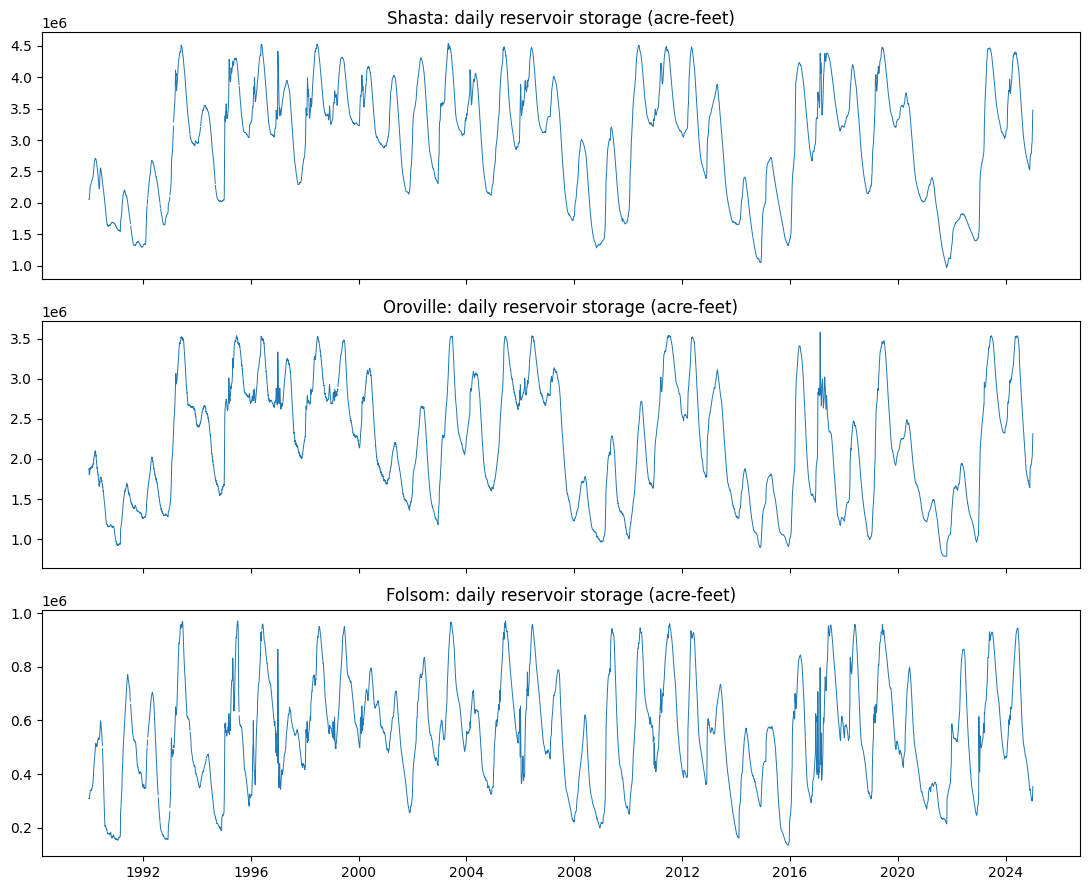

In [ ]:
# Cell 1 - Setup, download reservoir storage (CDEC) and weather (Open-Meteo), cache on Drive
import io
import os
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount("/content/drive")

SEED = 42
PROJECT_DIR = "/content/drive/MyDrive/reservoir_project"
DATA_DIR = f"{PROJECT_DIR}/data"
FIG_DIR = f"{PROJECT_DIR}/figures"
RESULTS_DIR = f"{PROJECT_DIR}/results"
for folder in (DATA_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(folder, exist_ok=True)

START_DATE, END_DATE = "1990-01-01", "2024-12-31"

# CDEC station id -> (name, latitude, longitude of the reservoir area)
RESERVOIRS = {
    "SHA": ("Shasta", 40.72, -122.42),
    "ORO": ("Oroville", 39.54, -121.49),
    "FOL": ("Folsom", 38.71, -121.16),
}

CDEC_URL = "https://cdec.water.ca.gov/dynamicapp/req/CSVDataServlet"
WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARS = ["temperature_2m_mean", "precipitation_sum", "snowfall_sum", "et0_fao_evapotranspiration"]


def request_with_retries(url, params, tries=4):
    for attempt in range(tries):
        response = requests.get(url, params=params, timeout=180)
        if response.status_code == 200:
            return response
        print(f"  HTTP {response.status_code}, waiting before retry {attempt + 1}/{tries}")
        time.sleep(10 * (attempt + 1))
    raise RuntimeError(f"Request failed: {url} -> {response.status_code}: {response.text[:200]}")


def parse_cdec_storage(csv_text):
    """CDEC CSV -> daily storage Series (acre-feet). Non-numeric entries such as '---' become missing."""
    raw = pd.read_csv(io.StringIO(csv_text))
    date_col = next(c for c in raw.columns if c.upper().replace("_", " ") in ("DATE TIME", "OBS DATE"))
    dates = pd.to_datetime(raw[date_col], errors="coerce").dt.normalize()
    values = pd.to_numeric(raw["VALUE"], errors="coerce")
    series = pd.Series(values.to_numpy(), index=dates, name="storage_af")
    series = series[series.index.notna()]
    series = series[~series.index.duplicated(keep="last")].sort_index()
    series.index.name = "date"
    return series


def download_reservoir(code, name, lat, lon):
    path = f"{DATA_DIR}/{name}.csv"
    if os.path.exists(path):
        return pd.read_csv(path, index_col="date", parse_dates=True)
    print(f"Downloading {name} ({code}) ...")
    storage_text = request_with_retries(CDEC_URL, {
        "Stations": code, "SensorNums": 15, "dur_code": "D",
        "Start": START_DATE, "End": END_DATE,
    }).text
    storage = parse_cdec_storage(storage_text)

    payload = request_with_retries(WEATHER_URL, {
        "latitude": lat, "longitude": lon, "daily": ",".join(WEATHER_VARS),
        "start_date": START_DATE, "end_date": END_DATE, "timezone": "UTC",
    }).json()["daily"]
    weather = pd.DataFrame({v: payload[v] for v in WEATHER_VARS}, index=pd.to_datetime(payload["time"]))
    weather.index.name = "date"

    frame = weather.join(storage, how="left")
    frame.to_csv(path)
    time.sleep(2)
    return frame


reservoir_frames = {
    name: download_reservoir(code, name, lat, lon) for code, (name, lat, lon) in RESERVOIRS.items()
}

# Quality checks
for name, frame in reservoir_frames.items():
    s = frame["storage_af"]
    print(f"\n{name}: {len(frame)} days, {frame.index[0].date()} to {frame.index[-1].date()}")
    print(f"  storage (acre-feet): min {s.min():,.0f}, median {s.median():,.0f}, max {s.max():,.0f}")
    print(f"  missing storage days: {int(s.isna().sum())} ({s.isna().mean():.1%}), "
          f"other columns missing: {int(frame.drop(columns='storage_af').isna().sum().sum())}")

fig, axes = plt.subplots(len(reservoir_frames), 1, figsize=(11, 3 * len(reservoir_frames)), sharex=True)
for ax, (name, frame) in zip(np.atleast_1d(axes), reservoir_frames.items()):
    ax.plot(frame.index, frame["storage_af"], lw=0.7)
    ax.set_title(f"{name}: daily reservoir storage (acre-feet)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_storage_overview.png", dpi=150)
plt.show()

In [2]:
# Cell 2 - Features, 30-day-ahead target, climatology and metrics
import numpy as np
import pandas as pd

HORIZON_DAYS = 30        # forecast the storage 30 days after the last observation
N_SPLITS = 5
TEST_SIZE_DAYS = 1095    # each test fold is 3 years
INFER_REPEATS = 20
LOW_PERCENTILE = 10      # "low-storage days" = the driest 10% of training anomalies


def build_dataset(frame, horizon=HORIZON_DAYS):
    """Features from day t (only data up to day t), target = storage at day t + horizon.
    Storage is in thousand acre-feet (TAF)."""
    storage = frame["storage_af"].interpolate(limit=7, limit_area="inside") / 1000.0

    features = pd.DataFrame(index=frame.index)
    features["storage_taf"] = storage
    features["change_7d"] = storage - storage.shift(7)
    features["change_30d"] = storage - storage.shift(30)
    for days in (7, 30, 90):
        features[f"precip_{days}d"] = frame["precipitation_sum"].rolling(days).sum()
    for days in (30, 90):
        features[f"snow_{days}d"] = frame["snowfall_sum"].rolling(days).sum()
    for days in (7, 30):
        features[f"temp_{days}d"] = frame["temperature_2m_mean"].rolling(days).mean()
    features["et0_30d"] = frame["et0_fao_evapotranspiration"].rolling(30).sum()

    day_of_year = np.asarray(frame.index.dayofyear)
    features["doy_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    features["doy_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

    target = storage.shift(-horizon).rename("target_storage_taf")
    target_dates = frame.index + pd.Timedelta(days=horizon)
    target_doy = pd.Series(np.asarray(target_dates.dayofyear), index=frame.index, name="target_doy")

    valid = features.notna().all(axis=1) & target.notna()
    return features[valid], target[valid], target_doy[valid]


def fit_climatology(y_train, doy_train, window=15):
    """Average storage per day of year (training data only), lightly smoothed."""
    daily_mean = pd.Series(np.asarray(y_train)).groupby(np.asarray(doy_train)).mean()
    daily_mean = daily_mean.reindex(range(1, 367)).interpolate(limit_direction="both")
    padded = pd.concat([daily_mean.iloc[-window:], daily_mean, daily_mean.iloc[:window]])
    smooth = padded.rolling(window, center=True, min_periods=1).mean()
    return smooth.iloc[window:-window]


def evaluate(y_true, y_pred, clim_test, low_threshold):
    """MAE, RMSE, bias, and the same errors on unusually low-storage (dry) days."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_pred - y_true
    low = (y_true - np.asarray(clim_test)) <= low_threshold
    return {
        "mae": float(np.mean(np.abs(error))),
        "rmse": float(np.sqrt(np.mean(error ** 2))),
        "bias": float(np.mean(error)),
        "n_low_days": int(low.sum()),
        "low_mae": float(np.mean(np.abs(error[low]))) if low.any() else np.nan,
        "low_bias": float(np.mean(error[low])) if low.any() else np.nan,
    }


for _name, _frame in reservoir_frames.items():
    _X, _y, _ = build_dataset(_frame)
    print(f"{_name}: {_X.shape[0]} samples, {_X.shape[1]} features, "
          f"{_X.index[0].date()} to {_X.index[-1].date()}")

Shasta: 12665 samples, 13 features, 1990-03-31 to 2024-12-01
Oroville: 12665 samples, 13 features, 1990-03-31 to 2024-12-01
Folsom: 12665 samples, 13 features, 1990-03-31 to 2024-12-01


In [3]:
# Cell 3 - Tool that measures time, CPU time and memory of any model step
import threading
import time
import psutil


class _PeakMemorySampler(threading.Thread):
    """Samples this process's memory in the background to find the peak."""

    def __init__(self, interval=0.01):
        super().__init__(daemon=True)
        self._process = psutil.Process()
        self._interval = interval
        self._halt = threading.Event()
        self.peak_rss = self._process.memory_info().rss

    def run(self):
        while not self._halt.is_set():
            self.peak_rss = max(self.peak_rss, self._process.memory_info().rss)
            time.sleep(self._interval)

    def stop(self):
        self._halt.set()
        self.join()
        self.peak_rss = max(self.peak_rss, self._process.memory_info().rss)


def profile_call(func, *args, repeats=1, **kwargs):
    """Run func(*args, **kwargs) and measure its cost.

    Returns (result, stats). wall_s and cpu_s are averages per call.
    peak_ram_mb is the extra memory used above the starting level.
    gpu_peak_mb stays 0 unless a CUDA GPU is used.
    """
    gpu = None
    try:
        import torch
        if torch.cuda.is_available():
            gpu = torch
            gpu.cuda.synchronize()
            gpu.cuda.reset_peak_memory_stats()
    except ImportError:
        pass

    sampler = _PeakMemorySampler()
    start_rss = sampler.peak_rss
    sampler.start()
    wall_start = time.perf_counter()
    cpu_start = time.process_time()

    result = None
    for _ in range(repeats):
        result = func(*args, **kwargs)

    if gpu is not None:
        gpu.cuda.synchronize()
    wall = (time.perf_counter() - wall_start) / repeats
    cpu = (time.process_time() - cpu_start) / repeats
    sampler.stop()

    stats = {
        "wall_s": wall,
        "cpu_s": cpu,
        "peak_ram_mb": max(sampler.peak_rss - start_rss, 0) / 1e6,
        "gpu_peak_mb": (gpu.cuda.max_memory_allocated() / 1e6) if gpu is not None else 0.0,
    }
    return result, stats


_, demo = profile_call(lambda: np.linalg.svd(np.random.rand(400, 400)))
print("Profiler works:", {k: round(v, 4) for k, v in demo.items()})

Profiler works: {'wall_s': 0.597, 'cpu_s': 0.6071, 'peak_ram_mb': 13.8732, 'gpu_peak_mb': 0.0}


In [4]:
# Cell 4 - Cross-validation runner, baselines (persistence, climatology, anomaly persistence) and Ridge
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display


def run_cv(models):
    """Expanding-window time series CV for {name: (fit_fn, predict_fn)}; returns one row per model and fold."""
    collected = []
    for location, frame in reservoir_frames.items():
        X, y, target_doy = build_dataset(frame)
        splitter = TimeSeriesSplit(n_splits=N_SPLITS, test_size=TEST_SIZE_DAYS, gap=HORIZON_DAYS)

        for fold, (train_idx, test_idx) in enumerate(splitter.split(X), start=1):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
            doy_train, doy_test = target_doy.iloc[train_idx], target_doy.iloc[test_idx]

            clim = fit_climatology(y_train, doy_train)
            train_anomaly = y_train.to_numpy() - clim.loc[doy_train.to_numpy()].to_numpy()
            low_threshold = float(np.percentile(train_anomaly, LOW_PERCENTILE))
            clim_test = clim.loc[doy_test.to_numpy()].to_numpy()
            period = f"{X_test.index[0].year}-{X_test.index[-1].year}"

            for model_name, (fit_fn, predict_fn) in models.items():
                model, train_stats = profile_call(fit_fn, X_train, y_train, doy_train)
                predictions, infer_stats = profile_call(
                    predict_fn, model, X_test, doy_test, repeats=INFER_REPEATS
                )
                scores = evaluate(y_test, predictions, clim_test, low_threshold)
                collected.append(
                    {
                        "location": location, "model": model_name, "fold": fold, "test_period": period,
                        **scores,
                        "train_s": train_stats["wall_s"],
                        "train_cpu_s": train_stats["cpu_s"],
                        "train_ram_mb": train_stats["peak_ram_mb"],
                        "infer_ms": infer_stats["wall_s"] * 1000,
                        "gpu_peak_mb": train_stats["gpu_peak_mb"],
                    }
                )
    return pd.DataFrame(collected)


# --- Baselines: no learning, or almost none ---
def persistence_fit(X_train, y_train, doy_train):
    return None


def persistence_predict(model, X_test, doy_test):
    return X_test["storage_taf"].to_numpy()  # in 30 days = same as today


def climatology_fit(X_train, y_train, doy_train):
    return fit_climatology(y_train, doy_train)


def climatology_predict(clim, X_test, doy_test):
    return clim.loc[doy_test.to_numpy()].to_numpy()


def anomaly_fit(X_train, y_train, doy_train):
    return fit_climatology(y_train, doy_train)


def anomaly_predict(clim, X_test, doy_test):
    """Seasonal normal 30 days from now, shifted by how far today's storage is from today's normal."""
    today_normal = clim.loc[np.asarray(X_test.index.dayofyear)].to_numpy()
    future_normal = clim.loc[doy_test.to_numpy()].to_numpy()
    return future_normal + (X_test["storage_taf"].to_numpy() - today_normal)


# --- Ridge regression predicting the CHANGE in storage over the next 30 days ---
def ridge_fit(X_train, y_train, doy_train):
    change = y_train - X_train["storage_taf"]
    model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
    model.fit(X_train, change)
    return model


def ridge_predict(model, X_test, doy_test):
    return X_test["storage_taf"].to_numpy() + model.predict(X_test)


MODELS = {
    "Persistence": (persistence_fit, persistence_predict),
    "Climatology": (climatology_fit, climatology_predict),
    "Anomaly persistence": (anomaly_fit, anomaly_predict),
    "Ridge": (ridge_fit, ridge_predict),
}
results = run_cv(MODELS)

summary = results.groupby(["location", "model"])[
    ["mae", "rmse", "bias", "low_mae", "low_bias", "train_s", "infer_ms", "train_ram_mb"]
].agg(["mean", "std"]).round(3)
display(summary)

results.to_csv(f"{RESULTS_DIR}/reservoir_folds.csv", index=False)
print("Saved fold results to", RESULTS_DIR)

mae              rmse              bias  \
                                 mean      std     mean      std     mean   
location model                                                              
Folsom   Anomaly persistence   55.718   10.196   72.897   13.567   -0.228   
         Climatology          129.045   28.972  155.230   34.878   -4.083   
         Persistence           83.240   18.485  103.221   22.008   -0.219   
         Ridge                 53.299    8.970   69.556   14.266    0.468   
Oroville Anomaly persistence  151.448   30.060  203.138   48.002   -5.321   
         Climatology          592.759  122.502  671.431  125.702  177.687   
         Persistence          224.902   49.653  285.232   69.016   -5.275   
         Ridge                121.294   32.629  170.452   56.686   -3.931   
Shasta   Anomaly persistence  157.268   14.998  220.496   34.757   -6.831   
         Climatology          739.236  215.867  839.541  230.928  104.252   
         Persistence          255.111   43.629  332.113   59.894   -6.690   
         Ridge                150.133   16.089  211.287   36.058   -7.519   

                                        low_mae           low_bias           \
                                  std      mean      std      mean      std   
location model                                                                
Folsom   Anomaly persistence    7.755    57.496   16.870    16.996    8.320   
         Climatology           97.064   314.817   33.773   314.817   33.773   
         Persistence            7.751    39.838   23.679    35.682   27.930   
         Ridge                 15.495    57.272    7.567    46.976   21.979   
Oroville Anomaly persistence   28.573    83.771   39.096    20.032   32.366   
         Climatology          359.643   998.567  139.288   998.567  139.288   
         Persistence           28.583   141.058   32.705    -0.129  136.953   
         Ridge                 30.587    61.848   23.540    28.430   25.631   
Shasta   Anomaly persistence   42.378   133.940   34.520    44.144   40.073   
         Climatology          583.146  1443.438  160.603  1443.438  160.603   
         Persistence           42.443   158.925   39.334   -13.046  135.626   
         Ridge                 68.107   120.515   34.607    80.622   35.467   

                             train_s        infer_ms        train_ram_mb  \
                                mean    std     mean    std         mean   
location model                                                             
Folsom   Anomaly persistence   0.002  0.000    1.156  0.169        0.004   
         Climatology           0.003  0.001    0.499  0.032        0.004   
         Persistence           0.000  0.000    0.013  0.002        0.004   
         Ridge                 0.008  0.000    2.002  0.077        0.004   
Oroville Anomaly persistence   0.002  0.000    1.079  0.047        0.004   
         Climatology           0.002  0.000    0.545  0.095        0.004   
         Persistence           0.000  0.000    0.015  0.005        0.004   
         Ridge                 0.009  0.002    2.037  0.117        0.231   
Shasta   Anomaly persistence   0.002  0.000    1.121  0.135        0.004   
         Climatology           0.002  0.000    0.505  0.035        0.004   
         Persistence           0.000  0.000    0.013  0.001        0.008   
         Ridge                 0.012  0.008    2.130  0.288        0.947   

                                     
                                std  
location model                       
Folsom   Anomaly persistence  0.000  
         Climatology          0.000  
         Persistence          0.000  
         Ridge                0.000  
Oroville Anomaly persistence  0.000  
         Climatology          0.000  
         Persistence          0.000  
         Ridge                0.507  
Shasta   Anomaly persistence  0.000  
         Climatology          0.000  
         Persistence          0.006  
         Ridge     

Saved fold results to /content/drive/MyDrive/reservoir_project/results
